# Lennard-Jones Square Directional Implicit Experiment

This notebook tests the new `ExactLineSearchDirectionalImplicitMultipleSystemOptimizer` with a Lennard-Jones force field using epsilon squared (`LJsquareFF`). The LJ systems are initialized with atom distances close enough to find true minima under the LJ potential.

In [1]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', '..')))

import copy
import torch
import numpy as np
import matplotlib.pyplot as plt

from geomatry.opt_Energy_approximated.optimizer import ExactLineSearchDirectionalImplicitMultipleSystemOptimizer
from geomatry.opt.loss import rmsd_loss
from geomatry.ff.graph import get_given_graph_builder
from geomatry.ff.springs import LJsquareFF, _random_lj_systems, _random_lj_ff_param

In [2]:
def min_pair_distance(Ra: torch.Tensor) -> float:
    dmat = torch.cdist(Ra, Ra)
    return float(torch.min(dmat + torch.eye(Ra.shape[0], device=Ra.device) * 1e6))

# Report a sample geometry distance to ensure systems are not too far for LJ minima.

In [3]:
systemN = 20
N = 10
N_pairs = 30
max_Za = 3
fixed_atom_indices = [0, 1]

# Build target LJ systems and parameters.
Ras, Zas, idx_is, idx_js = _random_lj_systems(systemN, N, N_pairs, max_Za, start_Za=1)
epsilon, sigma = _random_lj_ff_param(max_Za, epsilon_range=(0.7, 2.0), sigma_range=(0.9, 1.1))

ff = LJsquareFF(max_Za)
ff.reset_parameters(epsilon, sigma)
params_star = copy.deepcopy(ff.state_dict())

graph_builders = [get_given_graph_builder(idx_i, idx_j) for idx_i, idx_j in zip(idx_is, idx_js)]

# Print the distance statistics for the initial systems.
print('sample target epsilon', epsilon[1:, 1:].mean().item())
print('sample target sigma', sigma[1:, 1:].mean().item())
print('sample min distances', [min_pair_distance(Ra) for Ra in Ras[:3]])

sample target epsilon 1.319403991163606
sample target sigma 1.0126875042812797
sample min distances [0.3202402950018439, 0.7105836110116004, 0.7488854728312336]


/var/folders/d9/j9pnzj2s30jf7r3wxfwp0yz80000gn/T/ipykernel_88228/2868012326.py:3: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:837.)
  return float(torch.min(dmat + torch.eye(Ra.shape[0], device=Ra.device) * 1e6))


In [4]:
optimizer = ExactLineSearchDirectionalImplicitMultipleSystemOptimizer(
    Ras, Zas, graph_builders, ff, rmsd_loss,
    params_star=params_star,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)

# Perturb the LJ parameters before optimization.
perturbed_epsilon = torch.abs(epsilon.clone() + 0.3 * torch.randn_like(epsilon))
perturbed_sigma = torch.abs(sigma.clone() + 0.07 * torch.randn_like(sigma))
ff.reset_parameters(perturbed_epsilon, perturbed_sigma)
params_0 = copy.deepcopy(ff.state_dict())

print('start epsilon mean', params_0['epsilon'][1:,1:].mean().item())
print('start sigma mean', params_0['sigma'][1:,1:].mean().item())
print('target epsilon mean', params_star['epsilon'][1:,1:].mean().item())
print('target sigma mean', params_star['sigma'][1:,1:].mean().item())

/Users/soonhyun/Desktop/CollaborationWithWeiliang/GeometryOptimize/GeoMatry/geomatry/ff/utils.py:33: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/python_variable_indexing.cpp:353.)
  output = params[indices]    # (num_samples, ...)


start epsilon mean 1.297856573302456
start sigma mean 1.010644574418266
target epsilon mean 1.319403991163606
target sigma mean 1.0126875042812797


In [5]:
new_params = optimizer.optimize(params_0, lr=1e-5, epoch=25001, print_period=1000, e_size=0.0002, eN=9, sg=2)
print('optimization complete')

  0%|          | 0/25001 [00:00<?, ?it/s]/Users/soonhyun/Desktop/CollaborationWithWeiliang/GeometryOptimize/GeoMatry/geomatry/ff/utils.py:33: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/python_variable_indexing.cpp:353.)
  output = params[indices]    # (num_samples, ...)
  0%|          | 4/25001 [00:00<12:06, 34.42it/s, alpha_star=9.5019e-02, total_scale=4.214367e-04]

Iteration 0, alpha_star=1.0683e-01, total_scale=6.111325e-04


  4%|▍         | 1007/25001 [00:25<09:53, 40.43it/s, alpha_star=7.7538e-02, total_scale=3.387760e-04]

Iteration 1000, alpha_star=7.9087e-02, total_scale=5.004243e-04


  8%|▊         | 2005/25001 [00:50<09:34, 40.06it/s, alpha_star=7.4786e-02, total_scale=5.794734e-04]

...

Iteration 23000, alpha_star=2.3457e-03, total_scale=2.053540e-05


 96%|█████████▌| 24005/25001 [10:33<00:27, 36.32it/s, alpha_star=3.7800e-03, total_scale=2.722884e-05]

Iteration 24000, alpha_star=1.3037e-03, total_scale=1.266596e-05


100%|██████████| 25001/25001 [11:01<00:00, 37.77it/s, alpha_star=1.8972e-03, total_scale=1.617574e-05]

Iteration 25000, alpha_star=1.8972e-03, total_scale=1.617574e-05
optimization complete


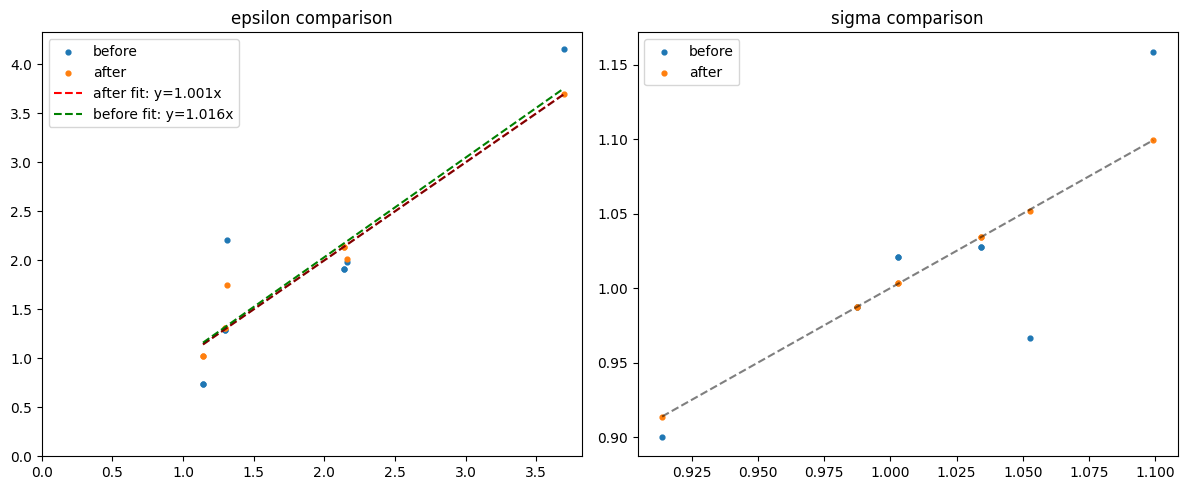

In [8]:
# Compare learned parameters before and after optimization.
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
target_eps = params_star['epsilon'][1:, 1:].detach().reshape(-1).cpu().numpy() ** 2
before_eps = params_0['epsilon'][1:, 1:].detach().reshape(-1).cpu().numpy() ** 2
after_eps = new_params['epsilon'][1:, 1:].detach().reshape(-1).cpu().numpy() ** 2
plt.scatter(target_eps, before_eps, label='before', s=12)
plt.scatter(target_eps, after_eps, label='after', s=12)

# Fit proportional relations for epsilon
slope_before_eps = (target_eps * before_eps).sum() / (target_eps * target_eps).sum()
slope_after_eps = (target_eps * after_eps).sum() / (target_eps * target_eps).sum()
line_x_eps = np.array([target_eps.min(), target_eps.max()])
plt.plot(line_x_eps, slope_after_eps * line_x_eps, 'r--', label=f'after fit: y={slope_after_eps:.3f}x')
plt.plot(line_x_eps, slope_before_eps * line_x_eps, 'g--', label=f'before fit: y={slope_before_eps:.3f}x')

plt.plot([target_eps.min(), target_eps.max()], [target_eps.min(), target_eps.max()], 'k--', alpha=0.5)
plt.title('epsilon comparison')
plt.legend()
plt.xlim(left=0)
plt.ylim(bottom=0)

plt.subplot(1, 2, 2)
target_sigma = params_star['sigma'][1:, 1:].detach().reshape(-1).cpu().numpy()
before_sigma = params_0['sigma'][1:, 1:].detach().reshape(-1).cpu().numpy()
after_sigma = new_params['sigma'][1:, 1:].detach().reshape(-1).cpu().numpy()
plt.scatter(target_sigma, before_sigma, label='before', s=12)
plt.scatter(target_sigma, after_sigma, label='after', s=12)
plt.plot([target_sigma.min(), target_sigma.max()], [target_sigma.min(), target_sigma.max()], 'k--', alpha=0.5)
plt.title('sigma comparison')
plt.legend()

plt.tight_layout()
plt.show()

In [9]:
# Fit proportional relations for LJ parameters.
for name, target_vals, before_vals, after_vals in [
    ('epsilon', target_eps, before_eps, after_eps),
    ('sigma', target_sigma, before_sigma, after_sigma)
]:
    slope_before = (target_vals * before_vals).sum() / (target_vals * target_vals).sum()
    slope_after = (target_vals * after_vals).sum() / (target_vals * target_vals).sum()
    print(f'{name} slope before: {slope_before:.4f}, after: {slope_after:.4f}')

epsilon slope before: 1.0165, after: 1.0007
sigma slope before: 0.9983, after: 1.0001
